An app logo defined in Python, with variants, and every asset generated from it.

A project keeps a module like this one; tooling imports ``logo`` and writes
SVG variants, PNGs at any size, ``.ico``/``.icns`` and favicons. Output is
deterministic, so stale assets can be detected by regenerating and comparing.
Run it as ``python logo.py [OUTPUT_DIR]`` or open ``logo.ipynb`` to see each variant.

In [1]:
import sys
import tempfile
from pathlib import Path
from typing import Literal

import svgwriter as svg

The logo is one function. `theme` picks a palette and `mono` draws it in a single color,
with the mark cut out of the ground by boolean subtraction.

In [2]:
SIZE = 100.0
PADDING = 4.0
THEMES = {
    "light": {"ground": "#0f766e", "mark": "#ffffff", "accent": "#fbbf24"},
    "dark": {"ground": "#99f6e4", "mark": "#042f2e", "accent": "#b45309"},
}


def logo(theme: Literal["light", "dark"] = "light", *, mono: bool = False) -> svg.Document:
    """The logo as a document; ``theme`` picks the palette and ``mono`` draws it in one color.

    Parameters
    ----------
    theme : {"light", "dark"}
        Color palette.
    mono : bool
        Single-color version (the mark is cut out of the ground).

    Returns
    -------
    Document
        A ``SIZE x SIZE`` drawing centred on the origin.
    """
    colors = THEMES[theme]
    doc = svg.Document(root=svg.Svg(view_box=(-SIZE / 2, -SIZE / 2, SIZE, SIZE)))
    ground = svg.rect(-SIZE / 2, -SIZE / 2, SIZE, SIZE, rx=SIZE * 0.22)
    pen = svg.path().move_to(-22, 18).line_to(0, -24).line_to(22, 18)
    mark = pen.to_path(stroke="black", stroke_width=12, fill="none").stroked(12)
    dot = svg.circle(0, 6, 7)
    if mono:
        doc += (ground - mark - dot).update(fill=colors["ground"])
        return doc
    doc += ground.update(fill=colors["ground"])
    doc += mark.update(fill=colors["mark"])
    doc += dot.update(fill=colors["accent"])
    return doc

The default light variant.

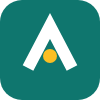

In [3]:
logo()

The dark variant.

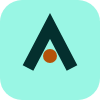

In [4]:
logo("dark")

The mono variant, a single path.

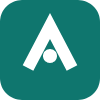

In [5]:
logo(mono=True)

Every asset a project usually needs comes from that one definition: SVG variants, PNGs at any size,
a multi-size `.ico`, an `.icns` and an apple-touch icon. Pass a folder as the first argument to choose
where they go. This cell only runs when the file is executed, not when it is imported
(the devkit `logo` tool imports `logo` from here).

In [6]:
if __name__ == "__main__":
    args = sys.argv[1:2]
    out = Path(args[0]) if args and not args[0].startswith("-") else Path(tempfile.mkdtemp(prefix="svgwriter-"))
    out.mkdir(parents=True, exist_ok=True)
    for theme in THEMES:
        logo(theme).save(out / f"logo-{theme}.svg")
    logo(mono=True).save(out / "logo-mono.svg")
    light = logo()
    for size in (16, 32, 48, 64, 128, 256, 512, 1024):
        light.save(out / f"logo-{size}.png", size=size, padding=PADDING)
    light.save(out / "favicon.ico", padding=PADDING, sizes=(16, 32, 48))
    light.save(out / "logo.icns", padding=PADDING)
    light.save(out / "apple-touch-icon.png", padding=PADDING, size=180, background=THEMES["light"]["ground"])
    print(f"saved {len(list(out.iterdir()))} files")

saved 14 files
